# 观测数据上的网格检查，以及采样、模型、解释对比

数据用 `vpd_gpp_1deg/obs` 里已经统一到 1° 的 ERA5 和 GIMMS LAI4g。

这个目录里没有观测 GPP。网格和时间检查包含现有的气温、露点、VPD、向下短波、表层土壤水和叶面积。方法测试需要一个响应变量，所以下面用 **GIMMS LAI** 做 `y`，驱动是 `vpd`、`t2m`、`ssrd`、`swvl1`。露点不进模型，因为 VPD 已经由气温和露点算出。以后有观测 GPP，只改 `TARGET`。

三组测试分开做，避免采样、模型和解释缠在一起：

1. 采样：模型固定为 ExtraTrees，解释固定为 `linear_treeshap`。
2. 模型：采样固定为 `random`。
3. 解释：采样和模型都固定。

每组都记录运行时间、解释忠实度和拟合性能。解释忠实度是：特征空间里相近的样本，SHAP 向量是否也相近。拟合用同一批留出的测试点。

In [1]:
import sys
import time
from pathlib import Path

root = Path.cwd().resolve()
if not (root / "src" / "rf_shap").exists() and (root.parent / "src" / "rf_shap").exists():
    root = root.parent
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))
fastforest_root = Path("/Users/huangfeini/Documents/FastForest")
if fastforest_root.exists() and str(fastforest_root) not in sys.path:
    sys.path.insert(0, str(fastforest_root))

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from rf_shap.cube.tabular import SampleTable
from rf_shap.explain.shap_explain import compute_shap
from rf_shap.models.registry import available_models, build_model
from rf_shap.models.sampling import sample_train
from rf_shap.predict.metrics import regression_metrics

plt.rcParams["font.sans-serif"] = ["PingFang SC", "Arial Unicode MS", "Heiti TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

OBS = Path("/Users/huangfeini/Documents/esm_case_data/vpd_gpp_1deg/obs")
FILES = {
    "t2m": "era5_monthly_1deg_1980-2014_2m_temperature.nc",
    "d2m": "era5_monthly_1deg_1980-2014_2m_dewpoint_temperature.nc",
    "vpd": "era5_monthly_1deg_1980-2014_vapour_pressure_deficit.nc",
    "ssrd": "era5_monthly_1deg_1980-2014_surface_solar_radiation_downwards.nc",
    "swvl1": "era5_monthly_1deg_1980-2014_volumetric_soil_water_layer_1.nc",
    "lai": "gimms_lai4g_monthly_1deg_1982-2014.nc",
}
FEATURES = ["vpd", "t2m", "ssrd", "swvl1"]
TARGET = "lai"
SEED = 42
N_POOL = 4000
N_TEST = 1000
N_TRAIN = 600
N_EXPLAIN = 60
print("models:", available_models())
print("target:", TARGET, "features:", FEATURES)

models: ['rf', 'extra_trees', 'hist_gbm', 'xgboost', 'lightgbm', 'lightgbm_rf', 'fastforest']
target: lai features: ['vpd', 't2m', 'ssrd', 'swvl1']


## 1. 读入，并按年月对齐

纬度、经度已经是同一套 1° 坐标。原始时间戳并不相同：ERA5 多在每月 1 日，向下短波是每月 1 日 06:00，GIMMS 在每月 15 日。这里把时间改成月初，再取交集。GIMMS 从 1982 年开始，所以公共时段是 1982–2014。

In [2]:
def open_monthly(path):
    dataset = xr.open_dataset(path)
    name = list(dataset.data_vars)[0]
    field = dataset[name].load()
    units = field.attrs.get("units", "")
    dataset.close()
    stamp = pd.to_datetime(field.time.values).to_period("M").to_timestamp()
    field = field.assign_coords(time=stamp.values)
    field = field.groupby("time").mean()
    field.attrs["units"] = units
    field.name = name
    return field


raw = {name: open_monthly(OBS / filename) for name, filename in FILES.items()}
common_time = raw["lai"].time.values
for field in raw.values():
    common_time = np.intersect1d(common_time, field.time.values)
cubes = {name: field.sel(time=common_time) for name, field in raw.items()}
reference = cubes["t2m"]

rows = []
for name, field in cubes.items():
    rows.append({
        "variable": name,
        "units": field.attrs.get("units", ""),
        "ntime_raw": int(raw[name].sizes["time"]),
        "ntime_common": int(field.sizes["time"]),
        "start": str(pd.Timestamp(field.time.values[0]).date()),
        "end": str(pd.Timestamp(field.time.values[-1]).date()),
        "lat_equal": bool(np.array_equal(field.lat.values, reference.lat.values)),
        "lon_equal": bool(np.array_equal(field.lon.values, reference.lon.values)),
        "time_equal": bool(np.array_equal(field.time.values, reference.time.values)),
        "lat0": float(field.lat.values[0]),
        "lat1": float(field.lat.values[-1]),
        "lon0": float(field.lon.values[0]),
        "lon1": float(field.lon.values[-1]),
    })
alignment = pd.DataFrame(rows)
alignment

,variable,units,ntime_raw,ntime_common,start,end,lat_equal,lon_equal,time_equal,lat0,lat1,lon0,lon1
0,t2m,K,420,396,1982-01-01,2014-12-01,True,True,True,90.0,-90.0,0.0,359.0
1,d2m,K,420,396,1982-01-01,2014-12-01,True,True,True,90.0,-90.0,0.0,359.0
2,vpd,kPa,420,396,1982-01-01,2014-12-01,True,True,True,90.0,-90.0,0.0,359.0
3,ssrd,J m**-2,420,396,1982-01-01,2014-12-01,True,True,True,90.0,-90.0,0.0,359.0
4,swvl1,m**3 m**-3,420,396,1982-01-01,2014-12-01,True,True,True,90.0,-90.0,0.0,359.0
5,lai,m2 m-2,396,396,1982-01-01,2014-12-01,True,True,True,90.0,-90.0,0.0,359.0


## 2. 画图看网格和时间

上图是 2001 年 7 月的原始场，用来看是不是同一张经纬网。中图是每个格点在公共时段里有多少个月是有效值。下图是陆地上的月平均，各自标准化之后画在一起，用来看时间是否合上。

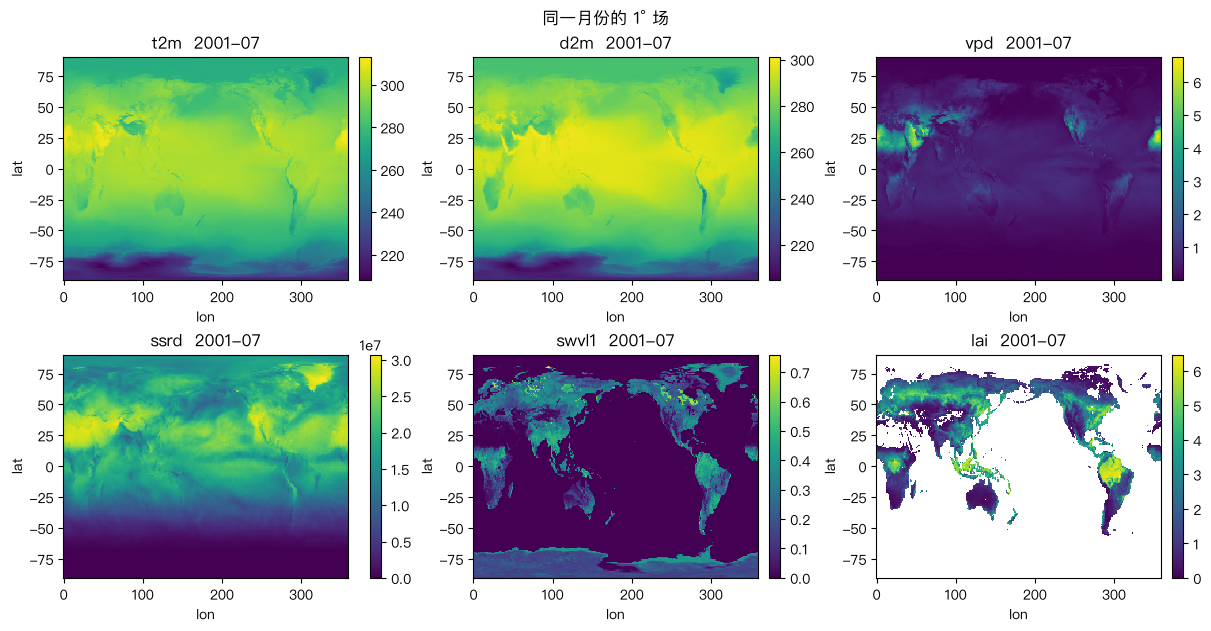

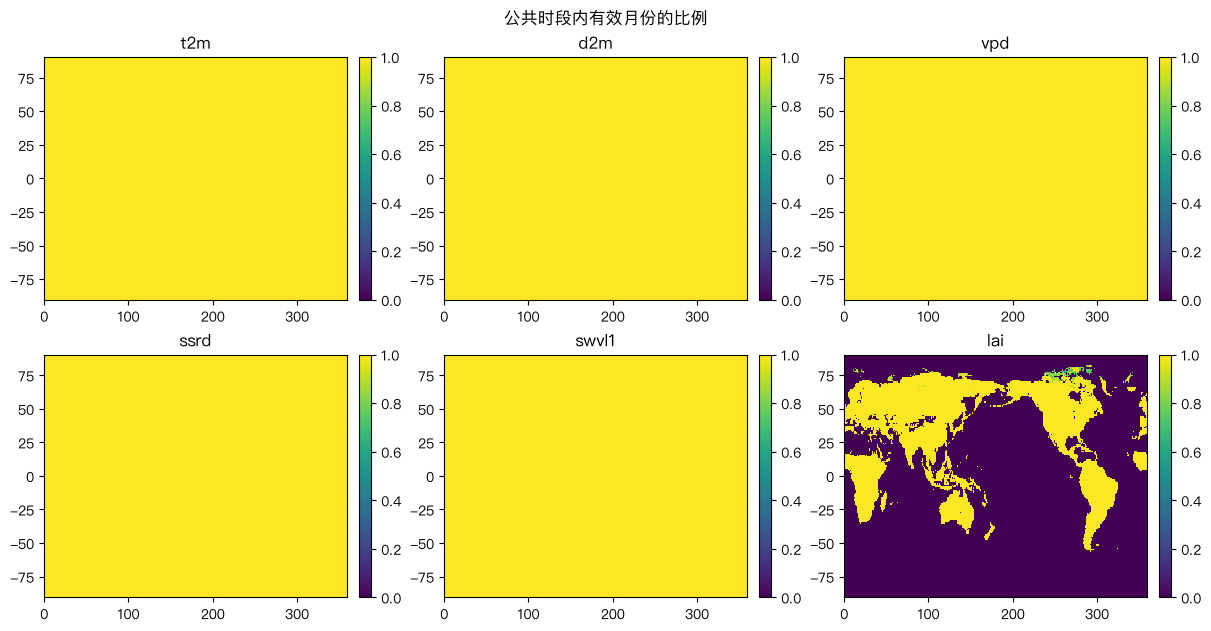

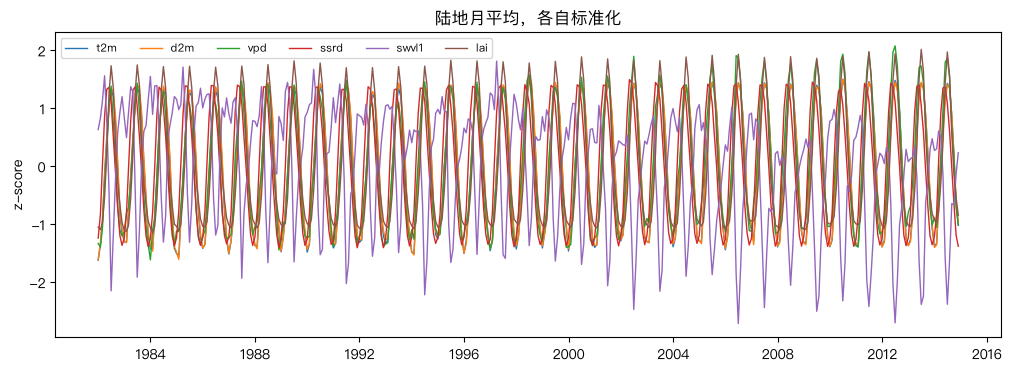

公共月份 396 1982-01-01 → 2014-12-01 网格 181 × 360


In [3]:
month = np.datetime64("2001-07-01")
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), constrained_layout=True)
for ax, (name, field) in zip(axes.ravel(), cubes.items()):
    image = ax.pcolormesh(field.lon, field.lat, field.sel(time=month), shading="auto")
    ax.set_title(f"{name}  2001-07")
    ax.set_xlabel("lon")
    ax.set_ylabel("lat")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle("同一月份的 1° 场")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), constrained_layout=True)
for ax, (name, field) in zip(axes.ravel(), cubes.items()):
    fraction = np.isfinite(field.values).mean(axis=0)
    image = ax.pcolormesh(field.lon, field.lat, fraction, shading="auto", vmin=0, vmax=1, cmap="viridis")
    ax.set_title(name)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle("公共时段内有效月份的比例")
plt.show()

land = np.isfinite(cubes["lai"].values) & np.isfinite(cubes["swvl1"].values)
fig, ax = plt.subplots(figsize=(10, 3.6), constrained_layout=True)
for name, field in cubes.items():
    series = np.array([
        np.nanmean(np.where(land[i], field.values[i], np.nan))
        for i in range(field.sizes["time"])
    ])
    series = (series - np.nanmean(series)) / np.nanstd(series)
    ax.plot(field.time.values, series, label=name, lw=1)
ax.legend(ncol=6, fontsize=8)
ax.set_title("陆地月平均，各自标准化")
ax.set_ylabel("z-score")
plt.show()

print(
    "公共月份", len(common_time),
    pd.Timestamp(common_time[0]).date(), "→", pd.Timestamp(common_time[-1]).date(),
    "网格", int(reference.sizes["lat"]), "×", int(reference.sizes["lon"]),
)

## 3. 抽样表和三个指标

从驱动和 LAI 同时有效的陆地点里抽 `N_POOL` 个，再留出固定的测试集。采样只在训练池里进行。

- 运行时间：采样、拟合、解释分开记。
- 拟合：测试集上的 R²、RMSE、MAE。
- 解释忠实度：在被解释的样本里，每个点找特征空间的 5 个最近邻，计算 SHAP 向量的余弦相似度，再减去随机配对的相似度。差值越大，相近样本的解释越像。

In [4]:
valid = np.ones(cubes[TARGET].shape, dtype=bool)
for name in FEATURES + [TARGET]:
    valid &= np.isfinite(cubes[name].values)
candidates = np.flatnonzero(valid.reshape(-1))
rng = np.random.default_rng(SEED)
chosen = rng.choice(candidates, size=N_POOL, replace=False)
time_i, lat_i, lon_i = np.unravel_index(chosen, cubes[TARGET].shape)

X = np.column_stack([cubes[name].values[time_i, lat_i, lon_i] for name in FEATURES])
y = cubes[TARGET].values[time_i, lat_i, lon_i]
lat = cubes[TARGET].lat.values[lat_i]
lon = cubes[TARGET].lon.values[lon_i]
when = cubes[TARGET].time.values[time_i]
index = pd.MultiIndex.from_arrays([when, lat, lon], names=["time", "lat", "lon"])
table = SampleTable(X, y, FEATURES, index, y_name=TARGET)

order = rng.permutation(table.n_samples)
test_pos = order[:N_TEST]
pool_pos = order[N_TEST:]
print(
    "有效陆地点", int(valid.sum()),
    "进入测试的点", table.n_samples,
    "训练池", len(pool_pos),
    "测试集", len(test_pos),
)


def explanation_fidelity(features, values, k=5, seed=SEED):
    features = np.asarray(features, dtype=np.float64)
    values = np.asarray(values, dtype=np.float64)
    n = len(features)
    k = min(k, n - 1)
    if k < 1:
        return {"neighbor_cosine": np.nan, "random_cosine": np.nan, "fidelity_gap": np.nan}
    center = features.mean(axis=0)
    scale = features.std(axis=0)
    scale[scale == 0] = 1.0
    z = (features - center) / scale
    distance = np.linalg.norm(z[:, None, :] - z[None, :, :], axis=2)
    np.fill_diagonal(distance, np.inf)
    neighbors = np.argpartition(distance, k, axis=1)[:, :k]
    norm = np.linalg.norm(values, axis=1, keepdims=True)
    norm[norm == 0] = 1.0
    unit = values / norm
    similarity = unit @ unit.T
    neighbor_score = np.take_along_axis(similarity, neighbors, axis=1).mean()
    random_index = np.random.default_rng(seed).integers(0, n, size=(n, k))
    random_score = np.take_along_axis(similarity, random_index, axis=1).mean()
    return {
        "neighbor_cosine": float(neighbor_score),
        "random_cosine": float(random_score),
        "fidelity_gap": float(neighbor_score - random_score),
    }


def explain_fitted(model, train_table, method):
    started = time.perf_counter()
    result = compute_shap(
        model,
        train_table,
        method=method,
        max_samples=N_EXPLAIN,
        background_size=20,
        n_jobs=1,
        seed=SEED,
    )
    elapsed = time.perf_counter() - started
    fidelity = explanation_fidelity(train_table.X[result.sample_positions], result.values)
    fidelity["explain_s"] = elapsed
    fidelity["explain_method"] = result.method
    return fidelity


def score_fit(model, train_pos):
    started = time.perf_counter()
    model.fit(table.X[train_pos], table.y[train_pos])
    fit_s = time.perf_counter() - started
    pred = model.predict(table.X[test_pos])
    metrics = regression_metrics(table.y[test_pos], pred)
    metrics["fit_s"] = fit_s
    return metrics

有效陆地点 6181239 进入测试的点 4000 训练池 3000 测试集 1000


## 4. 采样方法

模型固定为 40 棵 ExtraTrees，解释固定为 `linear_treeshap`。`clhs` 和 `aclhs` 的退火步数降到 150，只用于这次对比。

In [5]:
SAMPLERS = [
    "random", "stratified", "fscs", "cluster_medoid", "spatial", "systematic",
    "area", "kennard_stone", "maximin", "clhs", "process", "extreme",
    "active", "aclhs",
]
X_pool, y_pool = table.X[pool_pos], table.y[pool_pos]
lat_pool, lon_pool, time_pool = lat[pool_pos], lon[pool_pos], when[pool_pos]
sampling_rows = []
for method in SAMPLERS:
    row = {"method": method}
    try:
        started = time.perf_counter()
        picked = sample_train(
            X_pool, y_pool, method=method, n_samples=N_TRAIN, seed=SEED,
            lat=lat_pool, lon=lon_pool, time=time_pool, n_iter=150, active_rounds=2,
        )
        row["sample_s"] = time.perf_counter() - started
        train_pos = pool_pos[np.asarray(picked)]
        model = build_model("extra_trees", {"n_estimators": 40, "max_depth": 12, "n_jobs": -1}, seed=SEED)
        row.update(score_fit(model, train_pos))
        fidelity = explain_fitted(model, table.take(train_pos), "linear_treeshap")
        row.update(fidelity)
    except Exception as exc:
        row["error"] = f"{type(exc).__name__}: {exc}"
    sampling_rows.append(row)
    print(method, {k: row[k] for k in row if k != "method"})

sampling_result = pd.DataFrame(sampling_rows)
sampling_result

random {'sample_s': 0.00015050000001792796, 'n': 1000, 'r2': 0.6579728432172582, 'rmse': 0.8564352754019707, 'mae': 0.5972859654812891, 'bias': 0.03996701002964863, 'ubrmse': 0.8555022028388585, 'nse': 0.6579728432172582, 'kge': 0.7394487389453878, 'pearson_r': 0.8116800306289008, 'mape': 30.48406024133347, 'fit_s': 0.054739708997658454, 'neighbor_cosine': 0.6976861776604282, 'random_cosine': -0.027467146572731138, 'fidelity_gap': 0.7251533242331594, 'explain_s': 0.07796887500080629, 'explain_method': 'linear_treeshap'}


stratified {'sample_s': 0.000640124999335967, 'n': 1000, 'r2': 0.6755637393612852, 'rmse': 0.8341207892626973, 'mae': 0.577087308652651, 'bias': -0.03388159980177201, 'ubrmse': 0.8334323777458478, 'nse': 0.6755637393612852, 'kge': 0.749490581862039, 'pearson_r': 0.8222569637165108, 'mape': 24.2642574010707, 'fit_s': 0.015202165999653516, 'neighbor_cosine': 0.7103622411320138, 'random_cosine': 0.020359452036104977, 'fidelity_gap': 0.6900027890959088, 'explain_s': 0.0701672499999404, 'explain_method': 'linear_treeshap'}


fscs {'sample_s': 0.300535458001832, 'n': 1000, 'r2': 0.6633727426444758, 'rmse': 0.84964771006467, 'mae': 0.5934557544651556, 'bias': -0.003455490660918051, 'ubrmse': 0.8496406833493967, 'nse': 0.6633727426444758, 'kge': 0.7539780320909085, 'pearson_r': 0.8148119329420637, 'mape': 20.08010296935278, 'fit_s': 0.01919600000110222, 'neighbor_cosine': 0.6852523131826227, 'random_cosine': 0.002671197046803684, 'fidelity_gap': 0.6825811161358191, 'explain_s': 0.08912004199737567, 'explain_method': 'linear_treeshap'}


cluster_medoid {'sample_s': 0.3376697090025118, 'n': 1000, 'r2': 0.6604065862277548, 'rmse': 0.853382791943381, 'mae': 0.5952635165023238, 'bias': -0.030185078024568504, 'ubrmse': 0.8528487853363751, 'nse': 0.6604065862277548, 'kge': 0.7299828402016636, 'pearson_r': 0.81294201463081, 'mape': 20.255498823292235, 'fit_s': 0.01717083400217234, 'neighbor_cosine': 0.7996185143174273, 'random_cosine': -0.011296914844396119, 'fidelity_gap': 0.8109154291618234, 'explain_s': 0.07461737499761512, 'explain_method': 'linear_treeshap'}


spatial {'sample_s': 0.3037366250027844, 'n': 1000, 'r2': 0.6636936156122044, 'rmse': 0.8492426715914997, 'mae': 0.5940136324211448, 'bias': 0.014461305352423591, 'ubrmse': 0.8491195356952823, 'nse': 0.6636936156122044, 'kge': 0.7564641594292004, 'pearson_r': 0.8151667283893187, 'mape': 15.49646746977851, 'fit_s': 0.01762162500017439, 'neighbor_cosine': 0.767617473792895, 'random_cosine': 0.007413177008306251, 'fidelity_gap': 0.7602042967845888, 'explain_s': 0.0825920839997707, 'explain_method': 'linear_treeshap'}
systematic {'sample_s': 0.00044870900092064403, 'n': 1000, 'r2': 0.6757332733002004, 'rmse': 0.8339028261701297, 'mae': 0.5807485122764052, 'bias': 0.044436368556440536, 'ubrmse': 0.8327180391008986, 'nse': 0.6757332733002004, 'kge': 0.7512500275712278, 'pearson_r': 0.8226093274631686, 'mape': 14.52605452423831, 'fit_s': 0.034898582998721395, 'neighbor_cosine': 0.7412712043520605, 'random_cosine': -0.02641357467144947, 'fidelity_gap': 0.76768477902351, 'explain_s': 0.07527237

...

clhs {'sample_s': 0.013101541000651196, 'n': 1000, 'r2': 0.6657534446986146, 'rmse': 0.8466379313636979, 'mae': 0.5881050785457524, 'bias': 0.030578814291688586, 'ubrmse': 0.8460855293292256, 'nse': 0.6657534446986146, 'kge': 0.7420973257591656, 'pearson_r': 0.8162144003275573, 'mape': 29.375939540045334, 'fit_s': 0.017439541003113845, 'neighbor_cosine': 0.6937351381710312, 'random_cosine': -0.02285524673837797, 'fidelity_gap': 0.7165903849094092, 'explain_s': 0.07173654199868906, 'explain_method': 'linear_treeshap'}
process {'sample_s': 0.000448291000793688, 'n': 1000, 'r2': 0.6807419189417298, 'rmse': 0.8274375035268687, 'mae': 0.5778552015586915, 'bias': 0.05716388153085855, 'ubrmse': 0.8254605459324527, 'nse': 0.6807419189417298, 'kge': 0.7897895175397858, 'pearson_r': 0.8280005283010737, 'mape': 20.827884270636385, 'fit_s': 0.01768399999855319, 'neighbor_cosine': 0.7283107230430667, 'random_cosine': 0.008881895428692716, 'fidelity_gap': 0.719428827614374, 'explain_s': 0.0707597500

extreme {'sample_s': 0.000951458998315502, 'n': 1000, 'r2': 0.5874045536894158, 'rmse': 0.9406465503535788, 'mae': 0.643097469702324, 'bias': 0.26818840177175957, 'ubrmse': 0.9016046327782468, 'nse': 0.5874045536894158, 'kge': 0.7391469852753539, 'pearson_r': 0.81983015660829, 'mape': 6.24051006853198, 'fit_s': 0.017317374997219304, 'neighbor_cosine': 0.7516575910601168, 'random_cosine': -0.028986550113030286, 'fidelity_gap': 0.7806441411731471, 'explain_s': 0.06880295799783198, 'explain_method': 'linear_treeshap'}


active {'sample_s': 0.12000370800160454, 'n': 1000, 'r2': 0.6864109008758381, 'rmse': 0.8200583039104224, 'mae': 0.5661748331413115, 'bias': -0.03385609303266904, 'ubrmse': 0.8193591317468806, 'nse': 0.6864109008758381, 'kge': 0.7559945323762918, 'pearson_r': 0.8288225182498474, 'mape': 22.686743133140826, 'fit_s': 0.01745137499892735, 'neighbor_cosine': 0.6124259157853921, 'random_cosine': -0.04904622348249194, 'fidelity_gap': 0.6614721392678841, 'explain_s': 0.07560208300128579, 'explain_method': 'linear_treeshap'}


aclhs {'sample_s': 0.30887512499975855, 'n': 1000, 'r2': 0.6529887636111624, 'rmse': 0.8626527691047122, 'mae': 0.5984724900774588, 'bias': 0.06112729849658093, 'ubrmse': 0.8604843132925422, 'nse': 0.6529887636111624, 'kge': 0.7833709443047092, 'pearson_r': 0.8135409705744566, 'mape': 23.539352044699385, 'fit_s': 0.017587916998309083, 'neighbor_cosine': 0.7555308682740661, 'random_cosine': 0.05254390330454466, 'fidelity_gap': 0.7029869649695215, 'explain_s': 0.07224141700135078, 'explain_method': 'linear_treeshap'}


,method,sample_s,n,r2,rmse,mae,bias,ubrmse,nse,kge,pearson_r,mape,fit_s,neighbor_cosine,random_cosine,fidelity_gap,explain_s,explain_method
0,random,0.000151,1000,0.657973,0.856435,0.597286,0.039967,0.855502,0.657973,0.739449,0.811680,30.484060,0.054740,0.697686,-0.027467,0.725153,0.077969,linear_treeshap
1,stratified,0.000640,1000,0.675564,0.834121,0.577087,-0.033882,0.833432,0.675564,0.749491,0.822257,24.264257,0.015202,0.710362,0.020359,0.690003,0.070167,linear_treeshap
2,fscs,0.300535,1000,0.663373,0.849648,0.593456,-0.003455,0.849641,0.663373,0.753978,0.814812,20.080103,0.019196,0.685252,0.002671,0.682581,0.089120,linear_treeshap
3,cluster_medoid,0.337670,1000,0.660407,0.853383,0.595264,-0.030185,0.852849,0.660407,0.729983,0.812942,20.255499,0.017171,0.799619,-0.011297,0.810915,0.074617,linear_treeshap
4,spatial,0.303737,1000,0.663694,0.849243,0.594014,0.014461,0.849120,0.663694,0.756464,0.815167,15.496467,0.017622,0.767617,0.007413,0.760204,0.082592,linear_treeshap
5,systematic,0.000449,1000,0.675733,0.833903,0.580749,0.044436,0.832718,0.675733,0.751250,0.822609,14.526055,0.034899,0.741271,-0.026414,0.767685,0.075272,linear_treeshap
6,area,0.000371,1000,0.678545,0.830280,0.582252,0.076326,0.826764,0.678545,0.780678,0.826841,24.062940,0.019200,0.727514,0.001763,0.725752,0.074426,linear_treeshap
7,kennard_stone,0.165238,1000,0.671473,0.839363,0.575754,0.007592,0.839329,0.671473,0.778523,0.820908,22.600569,0.018009,0.692748,-0.016017,0.708765,0.074983,linear_treeshap
8,maximin,0.028689,1000,0.670319,0.840836,0.571526,-0.003603,0.840828,0.670319,0.790456,0.821596,15.774494,0.018016,0.756860,-0.014476,0.771335,0.073363,linear_treeshap
9,clhs,0.013102,1000,0.665753,0.846638,0.588105,0.030579,0.846086,0.665753,0.742097,0.816214,29.375940,0.017440,0.693735,-0.022855,0.716590,0.071737,linear_treeshap


## 5. 模型

采样固定为 `random`。sklearn 的森林用 `linear_treeshap`。XGBoost 和 LightGBM 用 `treeshap`。FastForest 不是 sklearn 树，用 `permutation`。

In [6]:
picked = sample_train(X_pool, y_pool, method="random", n_samples=N_TRAIN, seed=SEED)
train_pos = pool_pos[np.asarray(picked)]
train_table = table.take(train_pos)
MODEL_SPECS = [
    ("extra_trees", {"n_estimators": 40, "max_depth": 12, "n_jobs": -1}, "linear_treeshap"),
    ("rf", {"n_estimators": 40, "max_depth": 12, "n_jobs": -1}, "linear_treeshap"),
    ("hist_gbm", {"max_iter": 80, "max_depth": 8}, "treeshap"),
    ("lightgbm", {"n_estimators": 80, "n_jobs": -1}, "treeshap"),
    ("xgboost", {"n_estimators": 80, "n_jobs": -1}, "treeshap"),
    ("fastforest", {"n_estimators": 12, "max_depth": 8}, "permutation"),
]
model_rows = []
for name, params, explainer in MODEL_SPECS:
    row = {"model": name, "requested_explainer": explainer}
    if name not in available_models() and name != "fastforest":
        row["error"] = "not installed"
        model_rows.append(row)
        continue
    try:
        model = build_model(name, params, seed=SEED)
        row.update(score_fit(model, train_pos))
        row.update(explain_fitted(model, train_table, explainer))
    except Exception as exc:
        row["error"] = f"{type(exc).__name__}: {exc}"
    model_rows.append(row)
    print(name, {k: row[k] for k in row if k != "model"})

model_result = pd.DataFrame(model_rows)
model_result

extra_trees {'requested_explainer': 'linear_treeshap', 'n': 1000, 'r2': 0.6579728432172582, 'rmse': 0.8564352754019707, 'mae': 0.5972859654812891, 'bias': 0.03996701002964862, 'ubrmse': 0.8555022028388585, 'nse': 0.6579728432172582, 'kge': 0.7394487389453877, 'pearson_r': 0.8116800306289006, 'mape': 30.48406024133347, 'fit_s': 0.01802516599855153, 'neighbor_cosine': 0.6976861776604282, 'random_cosine': -0.027467146572731138, 'fidelity_gap': 0.7251533242331594, 'explain_s': 0.07461933399827103, 'explain_method': 'linear_treeshap'}


rf {'requested_explainer': 'linear_treeshap', 'n': 1000, 'r2': 0.6523952675991136, 'rmse': 0.8633901548149194, 'mae': 0.5900490714053113, 'bias': 0.0285875297299893, 'ubrmse': 0.8629167471866956, 'nse': 0.6523952675991136, 'kge': 0.7456703802722047, 'pearson_r': 0.8083510628998025, 'mape': 25.522312160765846, 'fit_s': 0.031156959001236828, 'neighbor_cosine': 0.7137760169683617, 'random_cosine': -0.03388729508502716, 'fidelity_gap': 0.7476633120533889, 'explain_s': 0.04853345900119166, 'explain_method': 'linear_treeshap'}


/opt/miniconda3/envs/esmvaltool/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


hist_gbm {'requested_explainer': 'treeshap', 'n': 1000, 'r2': 0.6420590561237534, 'rmse': 0.8761328039461519, 'mae': 0.5986784832429355, 'bias': 0.023542326642695677, 'ubrmse': 0.8758164470976751, 'nse': 0.6420590561237534, 'kge': 0.7620127236000818, 'pearson_r': 0.8038650828389686, 'mape': 18.614315201859192, 'fit_s': 0.37464354199983063, 'neighbor_cosine': 0.7179869502714977, 'random_cosine': -0.024552107403147394, 'fidelity_gap': 0.7425390576746451, 'explain_s': 0.17505816700213472, 'explain_method': 'treeshap'}
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000175 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 803
[LightGBM] [Info] Number of data points in the train set: 600, number of used features: 4
[LightGBM] [Info] Start training from score 1.483461
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best ga

xgboost {'requested_explainer': 'treeshap', 'n': 1000, 'r2': 0.5841372507597248, 'rmse': 0.9443636499802969, 'mae': 0.6453169591075785, 'bias': 0.03822848278498714, 'ubrmse': 0.9435895752434247, 'nse': 0.5841372507597248, 'kge': 0.737845469713653, 'pearson_r': 0.7715697370043255, 'mape': 5.900964387814051, 'fit_s': 0.1136652499990305, 'neighbor_cosine': 0.6848830514021601, 'random_cosine': -0.01895144522910406, 'fidelity_gap': 0.7038344966312642, 'explain_s': 0.035211709000577684, 'explain_method': 'treeshap'}


fastforest {'requested_explainer': 'permutation', 'n': 1000, 'r2': 0.5864906307699069, 'rmse': 0.9416877675025893, 'mae': 0.6507761014553073, 'bias': 0.009416286904745129, 'ubrmse': 0.9416406878448585, 'nse': 0.5864906307699069, 'kge': 0.7295676907656898, 'pearson_r': 0.7706809461076183, 'mape': 6.128948451066267, 'fit_s': 9.874674499998946, 'neighbor_cosine': 0.7442616789941747, 'random_cosine': -0.00308866826696895, 'fidelity_gap': 0.7473503472611437, 'explain_s': 8.743842250001762, 'explain_method': 'permutation'}


,model,requested_explainer,n,r2,rmse,mae,bias,ubrmse,nse,kge,pearson_r,mape,fit_s,neighbor_cosine,random_cosine,fidelity_gap,explain_s,explain_method
0,extra_trees,linear_treeshap,1000,0.657973,0.856435,0.597286,0.039967,0.855502,0.657973,0.739449,0.811680,30.484060,0.018025,0.697686,-0.027467,0.725153,0.074619,linear_treeshap
1,rf,linear_treeshap,1000,0.652395,0.863390,0.590049,0.028588,0.862917,0.652395,0.745670,0.808351,25.522312,0.031157,0.713776,-0.033887,0.747663,0.048533,linear_treeshap
2,hist_gbm,treeshap,1000,0.642059,0.876133,0.598678,0.023542,0.875816,0.642059,0.762013,0.803865,18.614315,0.374644,0.717987,-0.024552,0.742539,0.175058,treeshap
3,lightgbm,treeshap,1000,0.627616,0.893635,0.607067,0.028986,0.893164,0.627616,0.760057,0.796334,10.742708,0.116613,0.710439,-0.025069,0.735508,0.021329,treeshap
4,xgboost,treeshap,1000,0.584137,0.944364,0.645317,0.038228,0.943590,0.584137,0.737845,0.771570,5.900964,0.113665,0.684883,-0.018951,0.703834,0.035212,treeshap
5,fastforest,permutation,1000,0.586491,0.941688,0.650776,0.009416,0.941641,0.586491,0.729568,0.770681,6.128948,9.874674,0.744262,-0.003089,0.747350,8.743842,permutation


## 6. 解释方法

用上面同一棵 ExtraTrees。拟合指标相同，这一节比的是解释时间和解释忠实度。

In [7]:
fixed_model = build_model("extra_trees", {"n_estimators": 40, "max_depth": 12, "n_jobs": -1}, seed=SEED)
fixed_fit = score_fit(fixed_model, train_pos)
explain_rows = []
for method in ["treeshap", "fasttreeshap", "linear_treeshap", "permutation"]:
    row = {"method": method, "r2": fixed_fit["r2"], "rmse": fixed_fit["rmse"], "mae": fixed_fit["mae"], "fit_s": fixed_fit["fit_s"]}
    try:
        row.update(explain_fitted(fixed_model, train_table, method))
    except Exception as exc:
        row["error"] = f"{type(exc).__name__}: {exc}"
    explain_rows.append(row)
    print(method, {k: row[k] for k in row if k != "method"})

explain_result = pd.DataFrame(explain_rows)
explain_result

treeshap {'r2': 0.6579728432172582, 'rmse': 0.8564352754019707, 'mae': 0.5972859654812891, 'fit_s': 0.02132579200042528, 'neighbor_cosine': 0.6976861776604312, 'random_cosine': -0.02746714657273021, 'fidelity_gap': 0.7251533242331614, 'explain_s': 0.03333429099802743, 'explain_method': 'treeshap'}
fasttreeshap {'r2': 0.6579728432172582, 'rmse': 0.8564352754019707, 'mae': 0.5972859654812891, 'fit_s': 0.02132579200042528, 'neighbor_cosine': 0.6976861776604312, 'random_cosine': -0.027467146572730174, 'fidelity_gap': 0.7251533242331614, 'explain_s': 0.06037787500099512, 'explain_method': 'fasttreeshap'}


linear_treeshap {'r2': 0.6579728432172582, 'rmse': 0.8564352754019707, 'mae': 0.5972859654812891, 'fit_s': 0.02132579200042528, 'neighbor_cosine': 0.6976861776604282, 'random_cosine': -0.027467146572731138, 'fidelity_gap': 0.7251533242331594, 'explain_s': 0.07030208300056984, 'explain_method': 'linear_treeshap'}


IPython could not be loaded!


PermutationExplainer explainer:  22%|██▏       | 13/60 [00:00<?, ?it/s]

PermutationExplainer explainer:  25%|██▌       | 15/60 [00:11<00:17,  2.62it/s]

...

PermutationExplainer explainer: 100%|██████████| 60/60 [00:46<00:00,  1.30it/s]

PermutationExplainer explainer: 61it [00:46,  1.31it/s]                        

PermutationExplainer explainer: 61it [00:46,  1.03it/s]

permutation {'r2': 0.6579728432172582, 'rmse': 0.8564352754019707, 'mae': 0.5972859654812891, 'fit_s': 0.02132579200042528, 'neighbor_cosine': 0.7453791612030826, 'random_cosine': -0.008613529545459141, 'fidelity_gap': 0.7539926907485417, 'explain_s': 46.77938112500124, 'explain_method': 'permutation'}


,method,r2,rmse,mae,fit_s,neighbor_cosine,random_cosine,fidelity_gap,explain_s,explain_method
0,treeshap,0.657973,0.856435,0.597286,0.021326,0.697686,-0.027467,0.725153,0.033334,treeshap
1,fasttreeshap,0.657973,0.856435,0.597286,0.021326,0.697686,-0.027467,0.725153,0.060378,fasttreeshap
2,linear_treeshap,0.657973,0.856435,0.597286,0.021326,0.697686,-0.027467,0.725153,0.070302,linear_treeshap
3,permutation,0.657973,0.856435,0.597286,0.021326,0.745379,-0.008614,0.753993,46.779381,permutation


## 7. 三组结果放在一起

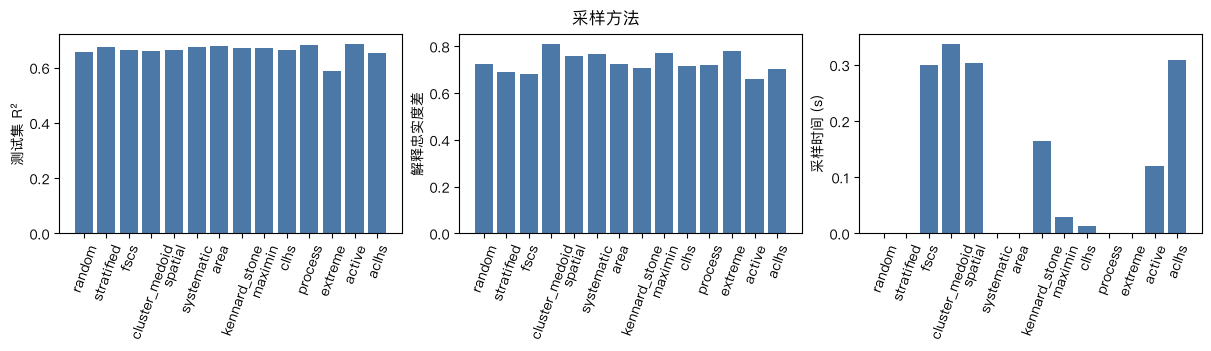

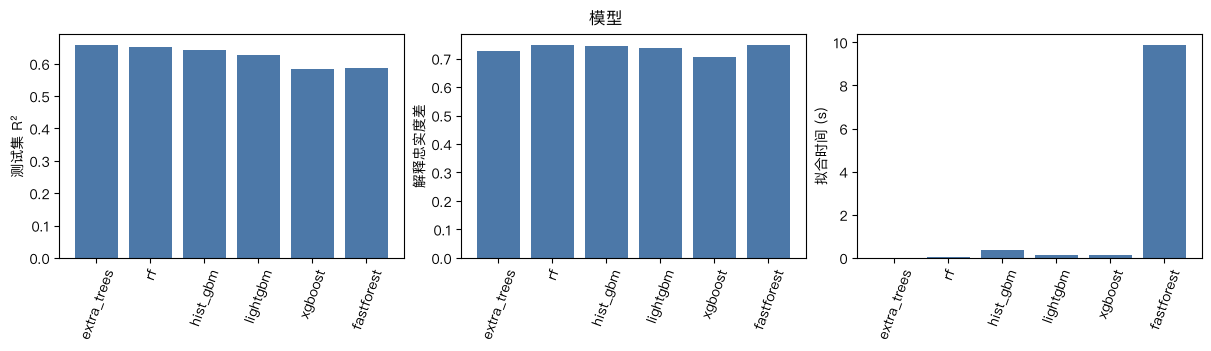

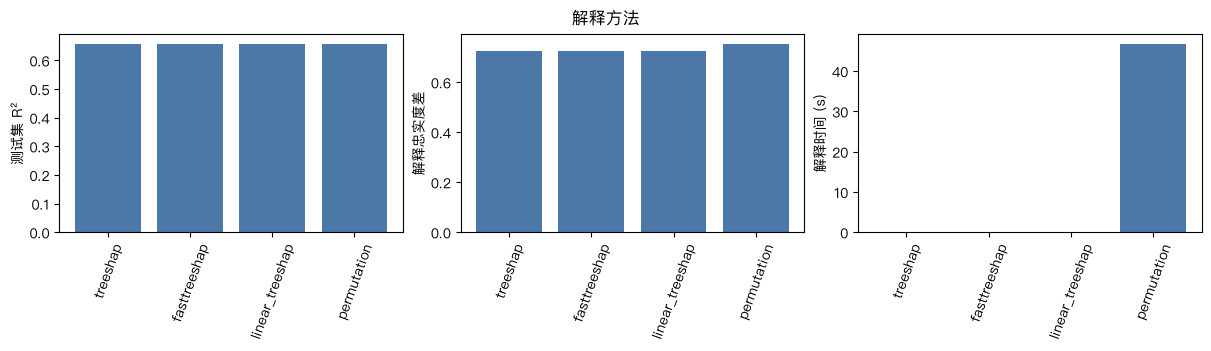

In [8]:
def show_bars(frame, label, title):
    plot_frame = frame.copy()
    if "r2" in plot_frame.columns:
        plot_frame = plot_frame[plot_frame["r2"].notna()]
    if plot_frame.empty:
        print(title, "没有成功的结果")
        return
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), constrained_layout=True)
    specs = [
        ("r2", "测试集 R²"),
        ("fidelity_gap", "解释忠实度差"),
        ("fit_s", "拟合时间 (s)"),
    ]
    if "sample_s" in plot_frame.columns:
        specs[2] = ("sample_s", "采样时间 (s)")
    if "explain_s" in plot_frame.columns and "sample_s" not in plot_frame.columns and label == "method":
        specs[2] = ("explain_s", "解释时间 (s)")
    for ax, (column, ylab) in zip(axes, specs):
        if column not in plot_frame.columns:
            ax.set_visible(False)
            continue
        ax.bar(plot_frame[label].astype(str), plot_frame[column], color="#4C78A8")
        ax.set_ylabel(ylab)
        ax.tick_params(axis="x", rotation=70)
    fig.suptitle(title)
    plt.show()


show_bars(sampling_result, "method", "采样方法")
show_bars(model_result, "model", "模型")
show_bars(explain_result, "method", "解释方法")

## 8. 各模型的 SHAP

横轴是输入变量，纵轴是该变量在同一批样本上的 SHAP。颜色区分模型。点是单个样本，短横线是这些样本的平均 SHAP。

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000200 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 803
[LightGBM] [Info] Number of data points in the train set: 600, number of used features: 4
[LightGBM] [Info] Start training from score 1.483461
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

underflow encountered in nextafter


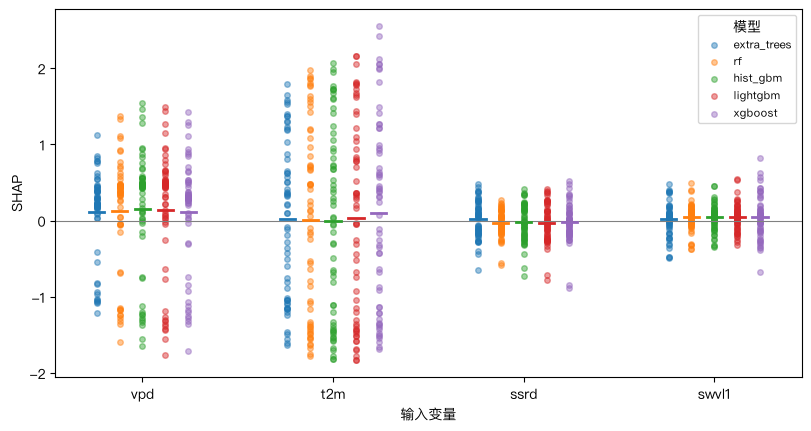

In [9]:
positions = np.random.default_rng(SEED).choice(train_table.n_samples, size=N_EXPLAIN, replace=False)
explain_table = train_table.take(np.sort(positions))
shap_by_model = {}
for name, params, explainer in MODEL_SPECS:
    if name == "fastforest":
        continue
    model = build_model(name, params, seed=SEED)
    model.fit(train_table.X, train_table.y)
    result = compute_shap(
        model,
        explain_table,
        method=explainer,
        max_samples=None,
        background_size=20,
        n_jobs=1,
        seed=SEED,
    )
    shap_by_model[name] = result.values

colors = dict(zip(shap_by_model, plt.cm.tab10.colors))
n_models = len(shap_by_model)
fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
for i, (name, values) in enumerate(shap_by_model.items()):
    shift = (i - (n_models - 1) / 2) * 0.12
    for j, feature in enumerate(explain_table.feature_names):
        ax.scatter(
            np.full(len(values), j) + shift,
            values[:, j],
            s=16,
            alpha=0.45,
            color=colors[name],
            label=name if j == 0 else None,
            zorder=2,
        )
        ax.plot(
            [j + shift - 0.04, j + shift + 0.04],
            [values[:, j].mean(), values[:, j].mean()],
            color=colors[name],
            lw=2,
            zorder=3,
        )
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xticks(range(len(explain_table.feature_names)))
ax.set_xticklabels(explain_table.feature_names)
ax.set_xlabel("输入变量")
ax.set_ylabel("SHAP")
ax.legend(title="模型", fontsize=8)
plt.show()

## 9. Dependence plot

四个子图对应四个输入变量。横轴是该变量的取值，纵轴是它自己的 SHAP。颜色表示模型。

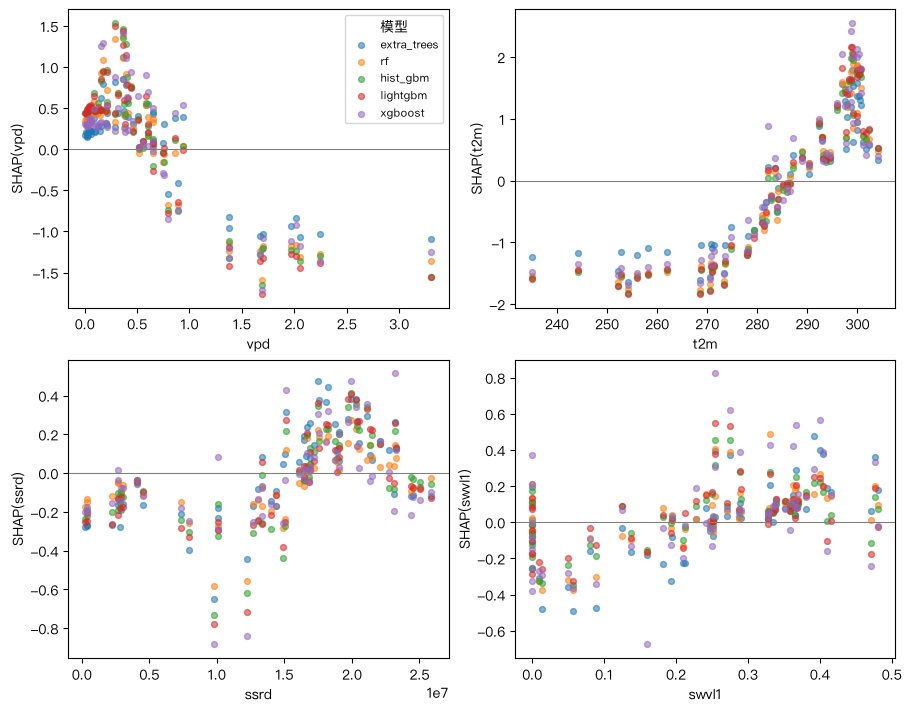

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7), constrained_layout=True)
for ax, j in zip(axes.ravel(), range(len(explain_table.feature_names))):
    feature = explain_table.feature_names[j]
    x = explain_table.X[:, j]
    for name, values in shap_by_model.items():
        ax.scatter(x, values[:, j], s=18, alpha=0.55, color=colors[name], label=name)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xlabel(feature)
    ax.set_ylabel(f"SHAP({feature})")
axes[0, 0].legend(title="模型", fontsize=8)
plt.show()
